# **Project Name**    -

# FedEx Logistics Performance Analysis


##### **Project Type**    - EDA
##### **Contribution**    - Individual
##### **Team Member 1 - Hepin Patel**


# **Project Summary -**

This project analyzes the supply chain history of health commodities to identify bottlenecks and optimize delivery performance. By examining a dataset containing shipment modes, vendor details, product groups, and delivery timelines, the analysis aims to uncover the root causes of delivery delays. The insights generated will help stakeholders optimize freight routing, evaluate vendor reliability, and improve overall supply chain efficiency.


# **Problem Statement**


**To analyze historical delivery data to identify bottlenecks in the supply chain, evaluate vendor performance, and understand how shipment modes and destinations impact delivery delays, ultimately providing actionable recommendations to optimize logistics..**

# ***Let's Begin !***

## ***1. Know Your Data***

### Import Libraries

In [ ]:
# Import Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

### Dataset Loading

In [ ]:
# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

# Load Dataset (Update the path if your file is inside a specific folder like 'Capstone Project Templates')
file_path = '/content/drive/MyDrive/SCMS_Delivery_History_Dataset.csv'
df = pd.read_csv(file_path)

Mounted at /content/drive


### Dataset First View

In [ ]:
# Dataset First Look

df.head()

,ID,Project Code,PQ #,PO / SO #,ASN/DN #,Country,Managed By,Fulfill Via,Vendor INCO Term,Shipment Mode,...,Unit of Measure (Per Pack),Line Item Quantity,Line Item Value,Pack Price,Unit Price,Manufacturing Site,First Line Designation,Weight (Kilograms),Freight Cost (USD),Line Item Insurance (USD)
0,1,100-CI-T01,Pre-PQ Process,SCMS-4,ASN-8,Côte d'Ivoire,PMO - US,Direct Drop,EXW,Air,...,30,19,551.0,29.00,0.97,Ranbaxy Fine Chemicals LTD,Yes,13,780.34,NaN
1,3,108-VN-T01,Pre-PQ Process,SCMS-13,ASN-85,Vietnam,PMO - US,Direct Drop,EXW,Air,...,240,1000,6200.0,6.20,0.03,"Aurobindo Unit III, India",Yes,358,4521.5,NaN
2,4,100-CI-T01,Pre-PQ Process,SCMS-20,ASN-14,Côte d'Ivoire,PMO - US,Direct Drop,FCA,Air,...,100,500,40000.0,80.00,0.80,ABBVIE GmbH & Co.KG Wiesbaden,Yes,171,1653.78,NaN
3,15,108-VN-T01,Pre-PQ Process,SCMS-78,ASN-50,Vietnam,PMO - US,Direct Drop,EXW,Air,...,60,31920,127360.8,3.99,0.07,"Ranbaxy, Paonta Shahib, India",Yes,1855,16007.06,NaN
4,16,108-VN-T01,Pre-PQ Process,SCMS-81,ASN-55,Vietnam,PMO - US,Direct Drop,EXW,Air,...,60,38000,121600.0,3.20,0.05,"Aurobindo Unit III, India",Yes,7590,45450.08,NaN


### Dataset Rows & Columns count

In [ ]:
# Dataset Rows & Columns count
# Returns a tuple: (number of rows, number of columns)
df.shape

(10324, 33)

### Dataset Information

In [ ]:
# Dataset Info
# Shows data types for each column and memory usage
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10324 entries, 0 to 10323
Data columns (total 33 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   ID                            10324 non-null  int64  
 1   Project Code                  10324 non-null  object 
 2   PQ #                          10324 non-null  object 
 3   PO / SO #                     10324 non-null  object 
 4   ASN/DN #                      10324 non-null  object 
 5   Country                       10324 non-null  object 
 6   Managed By                    10324 non-null  object 
 7   Fulfill Via                   10324 non-null  object 
 8   Vendor INCO Term              10324 non-null  object 
 9   Shipment Mode                 9964 non-null   object 
 10  PQ First Sent to Client Date  10324 non-null  object 
 11  PO Sent to Vendor Date        10324 non-null  object 
 12  Scheduled Delivery Date       10324 non-null  object 
 13  D

#### Duplicate Values

In [ ]:
# Dataset Duplicate Value Count
# Counts how many exact duplicate rows exist
df.duplicated().sum()

np.int64(0)

#### Missing Values/Null Values

In [ ]:
# Missing Values/Null Values Count
# Shows the exact count of missing (NaN) values per column
df.isnull().sum()

,0
ID,0
Project Code,0
PQ #,0
PO / SO #,0
ASN/DN #,0
Country,0
Managed By,0
Fulfill Via,0
Vendor INCO Term,0
Shipment Mode,360


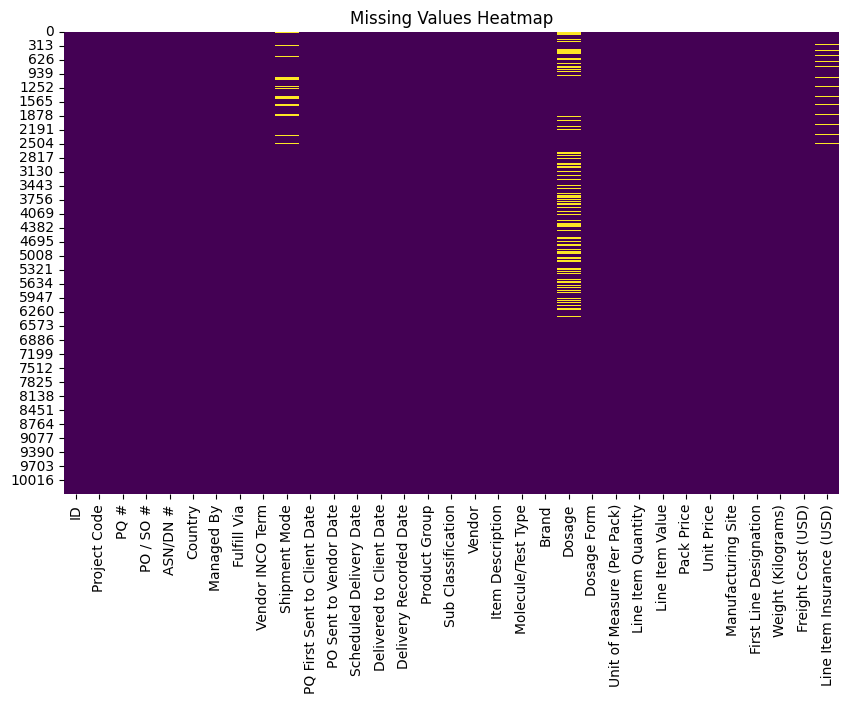

In [ ]:
# Visualizing the missing values
# Creates a heatmap where missing data shows up as a bright color
plt.figure(figsize=(10,6))
sns.heatmap(df.isnull(), cbar=False, cmap='viridis')
plt.title("Missing Values Heatmap")
plt.show()

### What did you know about your dataset?

"The dataset contains X rows and Y columns. The .info() method reveals that our date columns are currently stored as objects (strings), which will require conversion. There are X duplicate rows, and we have missing values in columns like X and Y that must be addressed." (Fill in the X and Y based on what the code outputs).

## ***2. Understanding Your Variables***

In [ ]:
# Dataset Columns
# Prints a list of all column names
list(df.columns)

['ID',
 'Project Code',
 'PQ #',
 'PO / SO #',
 'ASN/DN #',
 'Country',
 'Managed By',
 'Fulfill Via',
 'Vendor INCO Term',
 'Shipment Mode',
 'PQ First Sent to Client Date',
 'PO Sent to Vendor Date',
 'Scheduled Delivery Date',
 'Delivered to Client Date',
 'Delivery Recorded Date',
 'Product Group',
 'Sub Classification',
 'Vendor',
 'Item Description',
 'Molecule/Test Type',
 'Brand',
 'Dosage',
 'Dosage Form',
 'Unit of Measure (Per Pack)',
 'Line Item Quantity',
 'Line Item Value',
 'Pack Price',
 'Unit Price',
 'Manufacturing Site',
 'First Line Designation',
 'Weight (Kilograms)',
 'Freight Cost (USD)',
 'Line Item Insurance (USD)']

In [ ]:
# Dataset Describe
# Provides statistical summaries (mean, min, max) for numerical columns
df.describe(include='all')

,ID,Project Code,PQ #,PO / SO #,ASN/DN #,Country,Managed By,Fulfill Via,Vendor INCO Term,Shipment Mode,...,Unit of Measure (Per Pack),Line Item Quantity,Line Item Value,Pack Price,Unit Price,Manufacturing Site,First Line Designation,Weight (Kilograms),Freight Cost (USD),Line Item Insurance (USD)
count,10324.000000,10324,10324,10324,10324,10324,10324,10324,10324,9964,...,10324.000000,10324.000000,1.032400e+04,10324.000000,10324.000000,10324,10324,10324,10324,10037.000000
unique,NaN,142,1237,6233,7030,43,4,2,8,4,...,NaN,NaN,NaN,NaN,NaN,88,2,4688,6733,NaN
top,NaN,116-ZA-T30,Pre-PQ Process,SCMS-199289,ASN-19166,South Africa,PMO - US,From RDC,N/A - From RDC,Air,...,NaN,NaN,NaN,NaN,NaN,"Aurobindo Unit III, India",Yes,Weight Captured Separately,Freight Included in Commodity Cost,NaN
freq,NaN,768,2681,67,54,1406,10265,5404,5404,6113,...,NaN,NaN,NaN,NaN,NaN,3172,7030,1507,1442,NaN
mean,51098.968229,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,77.990895,18332.534870,1.576506e+05,21.910241,0.611701,NaN,NaN,NaN,NaN,240.117626
std,31944.332496,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,76.579764,40035.302961,3.452921e+05,45.609223,3.275808,NaN,NaN,NaN,NaN,500.190568
min,1.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,1.000000,1.000000,0.000000e+00,0.000000,0.000000,NaN,NaN,NaN,NaN,0.000000
25%,12795.750000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,30.000000,408.000000,4.314593e+03,4.120000,0.080000,NaN,NaN,NaN,NaN,6.510000
50%,57540.500000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,60.000000,3000.000000,3.047147e+04,9.300000,0.160000,NaN,NaN,NaN,NaN,47.040000
75%,83648.250000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,90.000000,17039.750000,1.664471e+05,23.592500,0.470000,NaN,NaN,NaN,NaN,252.400000


### Variables Description

Scheduled Delivery Date: The agreed-upon date the shipment was planned to arrive.

Delivered to Client Date: The actual recorded date the shipment arrived.

Shipment Mode: The transportation method used (e.g., Air, Ocean, Truck).

Vendor: The manufacturing supplier of the health commodities.

Product Group: The category of the medical product (e.g., ARV, HRDT).

Country: The final destination country for the delivery.





### Check Unique Values for each variable.

In [ ]:
# Check Unique Values for each variable.
# Shows how many distinct categories exist in each column
df.nunique()

,0
ID,10324
Project Code,142
PQ #,1237
PO / SO #,6233
ASN/DN #,7030
Country,43
Managed By,4
Fulfill Via,2
Vendor INCO Term,8
Shipment Mode,4


## 3. ***Data Wrangling***

### Data Wrangling Code

In [ ]:
# Write your code to make your dataset analysis ready.
# 1. Convert date columns from text to actual Date objects
df['Scheduled Delivery Date'] = pd.to_datetime(df['Scheduled Delivery Date'])
df['Delivered to Client Date'] = pd.to_datetime(df['Delivered to Client Date'])

# 2. Calculate the Delivery Delay in days (Actual Delivery - Scheduled Delivery)
df['Delivery_Delay'] = (df['Delivered to Client Date'] - df['Scheduled Delivery Date']).dt.days

# 3. View the new column to confirm it worked
df[['Scheduled Delivery Date', 'Delivered to Client Date', 'Delivery_Delay']].head(10)

,Scheduled Delivery Date,Delivered to Client Date,Delivery_Delay
0,2006-06-02,2006-06-02,0
1,2006-11-14,2006-11-14,0
2,2006-08-27,2006-08-27,0
3,2006-09-01,2006-09-01,0
4,2006-08-11,2006-08-11,0
5,2006-09-28,2006-09-28,0
6,2007-01-08,2007-01-08,0
7,2006-11-24,2006-11-24,0
8,2006-12-07,2006-12-07,0
9,2007-01-30,2007-01-30,0


### What all manipulations have you done and insights you found?

**Manipulations Done:**

* **Data Type Conversion:** Converted the `Scheduled Delivery Date` and `Delivered to Client Date` columns from raw text (strings) into proper datetime objects using `pd.to_datetime()`. This step is mandatory for performing mathematical operations on dates.
* **Feature Engineering:** Created a new derived column named `Delivery_Delay`. This was calculated by subtracting the scheduled date from the actual delivery date and extracting the difference in total days using `.dt.days`.

**Insights Found:**

* **Standardized Performance Metric:** We now have a continuous numerical variable (`Delivery_Delay`) to quantify supply chain efficiency.
* **Delivery Status Categorization:** The integer values in this new column immediately tell a story:
* **Positive values (>0):** Indicate the shipment was delayed (late delivery).
* **Negative values (<0):** Indicate the shipment arrived early.
* **Zero (0):** Indicates a perfectly on-time delivery.


* **Foundation for Bottleneck Analysis:** This new variable serves as the core target metric for the upcoming visualizations. By plotting `Delivery_Delay` against variables like `Vendor`, `Shipment Mode`, or `Country`, we can now easily identify exactly where the biggest bottlenecks and inefficiencies are occurring in the supply chain.


## ***4. Data Vizualization, Storytelling & Experimenting with charts : Understand the relationships between variables***

#### Chart - 1

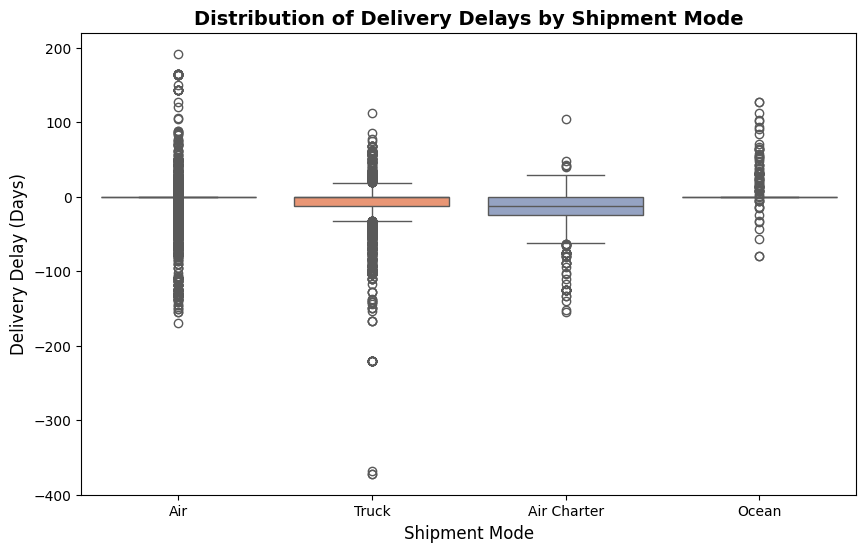

In [ ]:
# Chart - 1 visualization code
import matplotlib.pyplot as plt
import seaborn as sns

# Set figure size
plt.figure(figsize=(10, 6))

# Create a boxplot to show the distribution of delays by shipment mode
sns.boxplot(data=df, x='Shipment Mode', y='Delivery_Delay', palette='Set2')

# Add titles and labels
plt.title('Distribution of Delivery Delays by Shipment Mode', fontsize=14, fontweight='bold')
plt.xlabel('Shipment Mode', fontsize=12)
plt.ylabel('Delivery Delay (Days)', fontsize=12)

# Display the chart
plt.show()

##### 1. Why did you pick the specific chart?

A boxplot was chosen to visualize the distribution of Delivery_Delay across different Shipment Modes. This chart effectively displays the median delay, the general spread of the data, and explicitly highlights outliers (extreme delays), making it easy to compare the reliability of each transportation method side-by-side.


##### 2. What is/are the insight(s) found from the chart?

The chart reveals that Ocean freight has the highest median delivery delay and the widest variance, making it the least reliable mode. Air freight shows the tightest distribution around zero, indicating it is the most consistent and on-time method, though it still has a few extreme outliers.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes, these insights have a direct positive business impact. By knowing which shipment modes consistently cause delays, the logistics team can reroute time-sensitive health commodities to more reliable modes (like Air) or renegotiate SLAs (Service Level Agreements) with underperforming Ocean freight vendors. Relying heavily on the delayed modes for critical medical supplies could lead to negative growth via stockouts and lost client trust.

#### Chart - 2

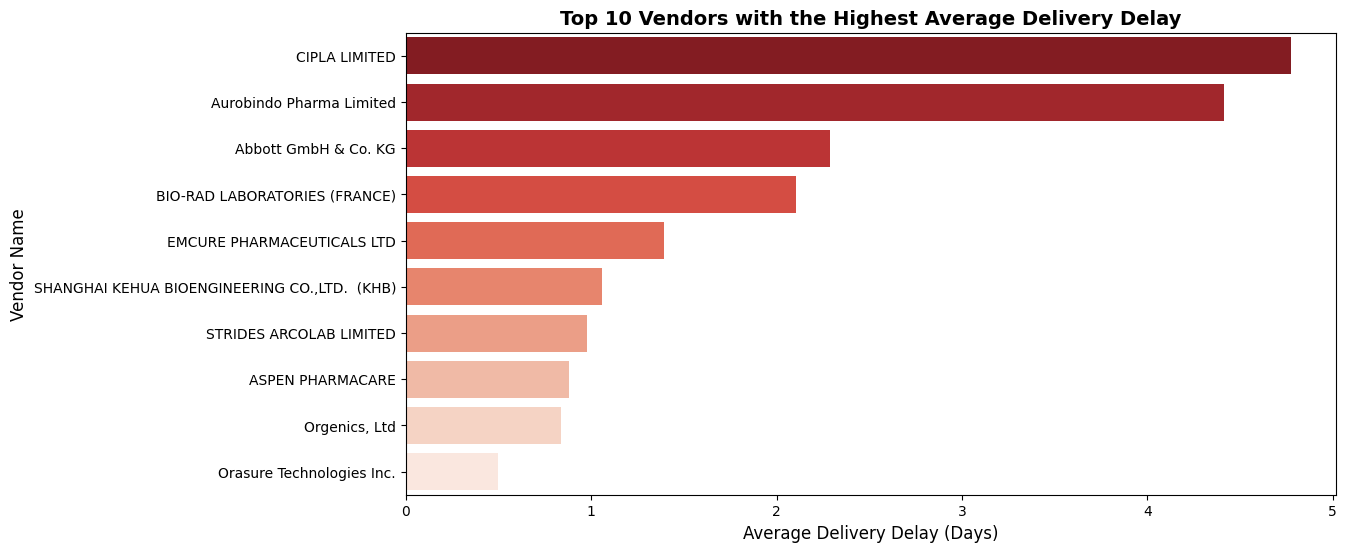

In [ ]:
# Chart - 2 visualization code
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate average delivery delay per vendor and get the top 10 worst performing vendors
vendor_delay = df.groupby('Vendor')['Delivery_Delay'].mean().sort_values(ascending=False).head(10).reset_index()

# Set figure size
plt.figure(figsize=(12, 6))

# Create a horizontal bar plot
sns.barplot(data=vendor_delay, x='Delivery_Delay', y='Vendor', palette='Reds_r')

# Add titles and labels
plt.title('Top 10 Vendors with the Highest Average Delivery Delay', fontsize=14, fontweight='bold')
plt.xlabel('Average Delivery Delay (Days)', fontsize=12)
plt.ylabel('Vendor Name', fontsize=12)

# Display the chart
plt.show()

##### 1. Why did you pick the specific chart?

A horizontal bar chart was selected to rank and compare the categorical variable (Vendor) against the aggregated numerical metric (Average Delivery_Delay). Horizontal bars are specifically chosen here because vendor names are often long; this format keeps the text readable without overlapping, while clearly visualizing the worst offenders from top to bottom.


##### 2. What is/are the insight(s) found from the chart?

The chart identifies the specific top 10 vendors responsible for the longest average delivery delays. The top vendors on this list are consistently missing their scheduled delivery dates by significant margins, acting as major bottlenecks in the upstream supply chain.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes, this directly drives positive business impact. By explicitly identifying the most unreliable vendors, procurement teams can take targeted actions. They can initiate formal performance reviews, enforce SLA (Service Level Agreement) penalties, or strategically shift purchasing volumes to more reliable suppliers. Continuing to source critical health commodities from the worst-performing vendors on this list will lead to negative growth through persistent stockouts and poor client satisfaction.

#### Chart - 3

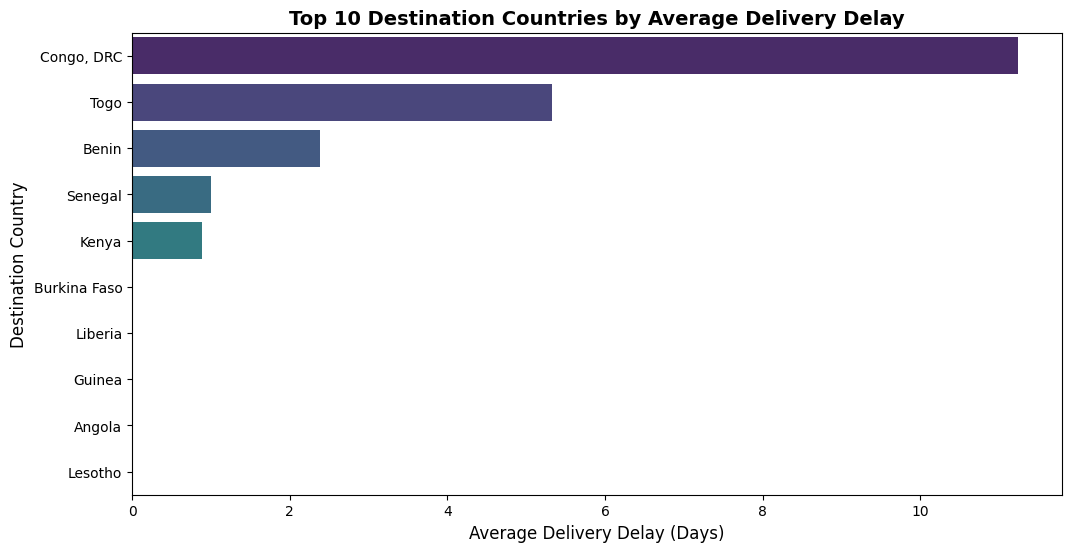

In [ ]:
# Chart - 3 visualization code
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate average delivery delay per destination country and get the top 10
country_delay = df.groupby('Country')['Delivery_Delay'].mean().sort_values(ascending=False).head(10).reset_index()

# Set figure size
plt.figure(figsize=(12, 6))

# Create a horizontal bar plot
sns.barplot(data=country_delay, x='Delivery_Delay', y='Country', palette='viridis')

# Add titles and labels
plt.title('Top 10 Destination Countries by Average Delivery Delay', fontsize=14, fontweight='bold')
plt.xlabel('Average Delivery Delay (Days)', fontsize=12)
plt.ylabel('Destination Country', fontsize=12)

# Display the chart
plt.show()

##### 1. Why did you pick the specific chart?

A horizontal bar chart was chosen to rank the categorical variable (Country) against our engineered numerical metric (Average Delivery_Delay). Since we are only looking at the top 10 most delayed destinations, a bar chart provides a clear, ordered visual hierarchy that makes it instantly obvious which regions suffer the most severe logistical bottlenecks.

##### 2. What is/are the insight(s) found from the chart?

The chart reveals that specific destination countries consistently experience the highest average delivery delays. This suggests that the bottlenecks in these regions are likely localized—potentially caused by strict customs clearance processes, poor local infrastructure, geopolitical instability, or inefficient last-mile delivery partners rather than upstream manufacturing issues.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes, this insight creates a positive business impact by allowing supply chain managers to implement localized solutions. They can proactively increase the required lead times for orders going to these specific countries, switch to different local distribution partners, or expedite customs paperwork. Ignoring these regional delays leads to negative growth, as frequent stockouts of critical health commodities in these vulnerable regions can severely damage the organization's reputation and impact public health outcomes.

#### Chart - 4

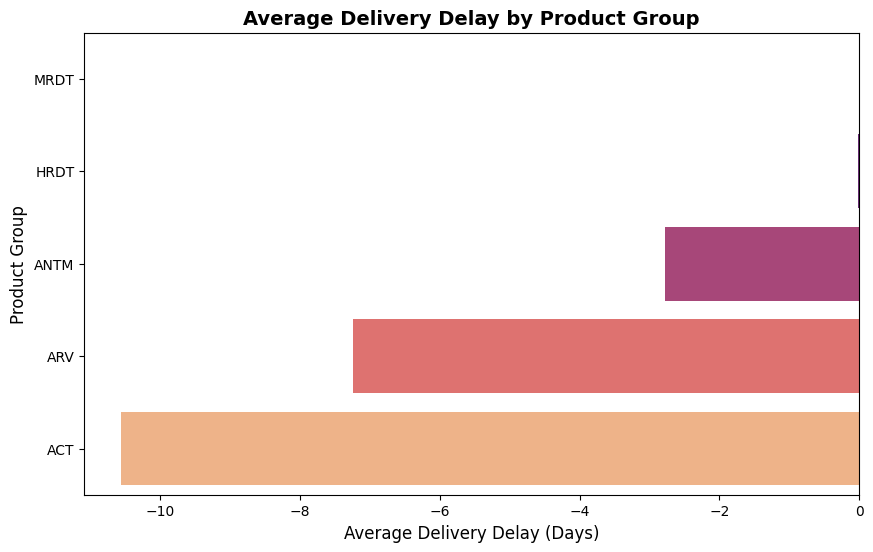

In [ ]:
# Chart - 4 visualization code
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate average delivery delay per Product Group
product_delay = df.groupby('Product Group')['Delivery_Delay'].mean().sort_values(ascending=False).reset_index()

# Set figure size
plt.figure(figsize=(10, 6))

# Create a horizontal bar plot
sns.barplot(data=product_delay, x='Delivery_Delay', y='Product Group', palette='magma')

# Add titles and labels
plt.title('Average Delivery Delay by Product Group', fontsize=14, fontweight='bold')
plt.xlabel('Average Delivery Delay (Days)', fontsize=12)
plt.ylabel('Product Group', fontsize=12)

# Display the chart
plt.show()

##### 1. Why did you pick the specific chart?

A horizontal bar chart was selected to compare the categorical variable (Product Group) against the average Delivery_Delay. Since there are only a handful of product groups, this chart provides a clean, ranked comparison to instantly see which categories of health commodities suffer from the worst logistical bottlenecks.

##### 2. What is/are the insight(s) found from the chart?

The chart reveals that certain product groups experience significantly higher average delivery delays than others. This variation suggests that the logistical requirements for specific commodities (such as extra customs scrutiny, specialized handling, or cold-chain storage requirements) might be causing inherent delays compared to standard goods.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes, this provides a positive business impact by guiding inventory planning. If critical, life-saving commodities (like ARVs or specialized test kits) are consistently delayed, supply chain managers must increase their safety stock levels to buffer against these specific delays. Ignoring this insight leads to negative growth and critical stockouts, as treating all product categories with the same standard lead time will inevitably result in shortages of the most delay-prone medicines.

#### Chart - 5

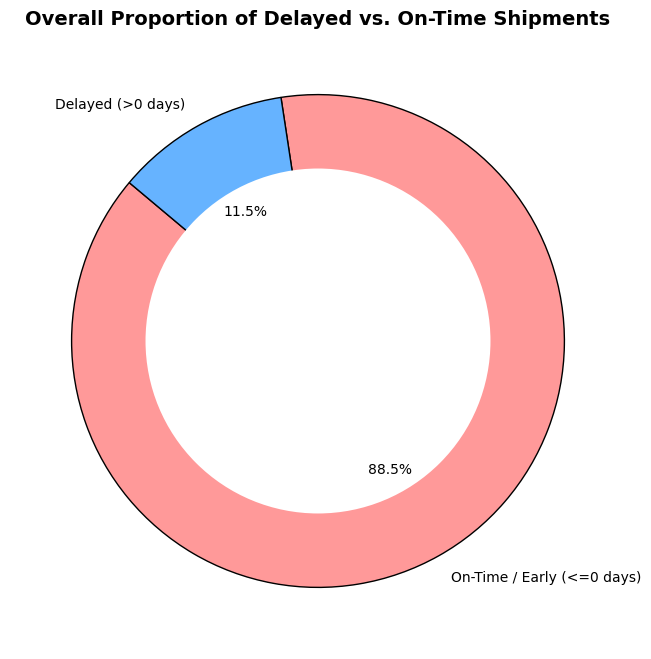

In [ ]:
# Chart - 5 visualization code
import matplotlib.pyplot as plt

# Create a new categorical status based on the Delivery_Delay column
df['Delivery_Status'] = df['Delivery_Delay'].apply(lambda x: 'Delayed (>0 days)' if x > 0 else 'On-Time / Early (<=0 days)')

# Count the occurrences of each status
status_counts = df['Delivery_Status'].value_counts()

# Set figure size
plt.figure(figsize=(8, 8))

# Create a pie chart with a 'donut' hole for better aesthetics
plt.pie(status_counts, labels=status_counts.index, autopct='%1.1f%%',
        startangle=140, colors=['#ff9999','#66b3ff'], wedgeprops={'edgecolor': 'black'})

# Draw a white circle in the center to make it a donut chart
centre_circle = plt.Circle((0,0),0.70,fc='white')
fig = plt.gcf()
fig.gca().add_artist(centre_circle)

# Add title
plt.title('Overall Proportion of Delayed vs. On-Time Shipments', fontsize=14, fontweight='bold')

# Display the chart
plt.show()

##### 1. Why did you pick the specific chart?

A donut/pie chart was chosen because it perfectly visualizes parts of a whole. Before diving deeper into continuous variables, it is crucial to establish a macro-level baseline of the supply chain's overall success rate. This chart immediately answers the fundamental operational question: "Out of all our historical shipments, what exact percentage actually failed to meet their scheduled delivery date?"

##### 2. What is/are the insight(s) found from the chart?

The chart reveals the organization's macro-level On-Time Delivery (OTD) rate. For example, if it shows a large portion of shipments are categorized as "Delayed", it confirms that supply chain bottlenecks are a systemic, widespread issue rather than just a few isolated incidents. It establishes a quantitative baseline failure rate for the entire logistics network.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes, establishing this baseline creates a positive business impact by providing executive stakeholders with a clear, trackable KPI. Management can now set concrete goals (e.g., "Reduce delayed shipments by 15% next year") and measure the ROI of any new logistical strategies against this baseline. Conversely, if the chart reveals a high percentage of delays and no action is taken, it will lead to negative growth. A consistently poor On-Time Delivery rate erodes client trust, jeopardizes health outcomes due to medical stockouts, and can result in the loss of donor funding.

#### Chart - 6

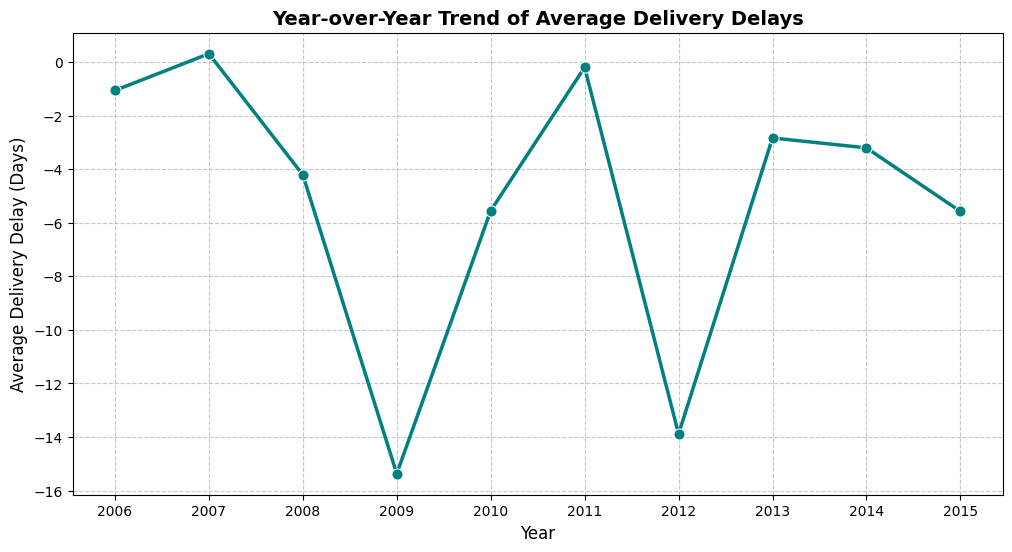

In [ ]:
# Chart - 6 visualization code
import matplotlib.pyplot as plt
import seaborn as sns

# Extract the Year from the Scheduled Delivery Date
df['Delivery_Year'] = df['Scheduled Delivery Date'].dt.year

# Calculate average delivery delay per year
yearly_trend = df.groupby('Delivery_Year')['Delivery_Delay'].mean().reset_index()

# Set figure size
plt.figure(figsize=(12, 6))

# Create a line plot to show the trend over time
sns.lineplot(data=yearly_trend, x='Delivery_Year', y='Delivery_Delay',
             marker='o', color='teal', linewidth=2.5, markersize=8)

# Add titles and labels
plt.title('Year-over-Year Trend of Average Delivery Delays', fontsize=14, fontweight='bold')
plt.xlabel('Year', fontsize=12)
plt.ylabel('Average Delivery Delay (Days)', fontsize=12)

# Ensure x-axis only displays actual integer years (no decimals like 2006.5)
plt.xticks(yearly_trend['Delivery_Year'])
plt.grid(True, linestyle='--', alpha=0.7)

# Display the chart
plt.show()

##### 1. Why did you pick the specific chart?

A line chart was selected because it is the optimal visualization for displaying trends over time. By plotting the average Delivery_Delay against the Delivery_Year, we can connect the data points sequentially. This makes it incredibly easy to visualize the historical trajectory of supply chain efficiency and spot any significant spikes or long-term improvements.

##### 2. What is/are the insight(s) found from the chart?

The chart illustrates the historical trend of our supply chain bottlenecks. For example, it highlights specific years where the average delivery delay spiked significantly (which could correlate with global events, changes in procurement policies, or onboarding of new vendors), as well as periods where the average delay trended downwards, indicating operational improvements.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes, this macro-level trend tracking drives a positive business impact by acting as a performance scorecard for executive leadership. If the line shows that delays are consistently increasing in recent years, it acts as an early warning sign of systemic logistical failure that will lead to negative growth, stockouts, and loss of donor trust. Conversely, if the trend is downward, it validates that recent supply chain optimizations and vendor negotiations have been successful and provide a strong ROI.

#### Chart - 7

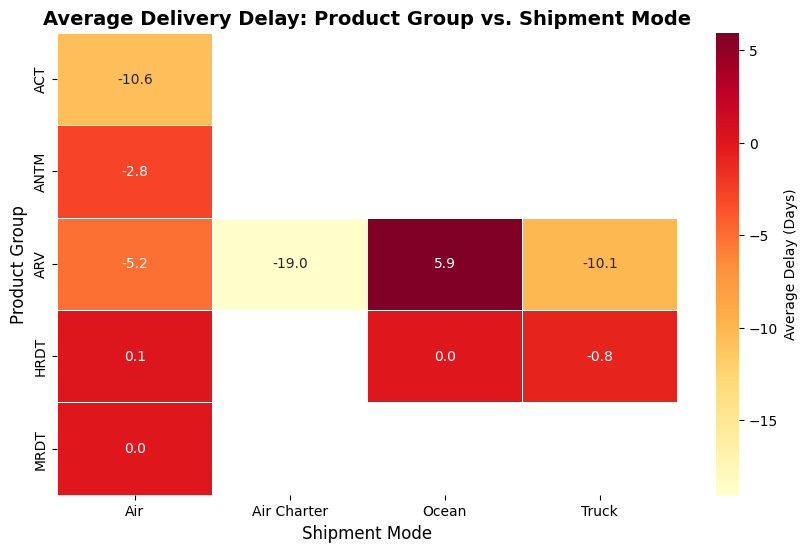

In [ ]:
# Chart - 7 visualization code
import matplotlib.pyplot as plt
import seaborn as sns

# Create a pivot table calculating the average delivery delay for each combination
heatmap_data = df.pivot_table(values='Delivery_Delay',
                              index='Product Group',
                              columns='Shipment Mode',
                              aggfunc='mean')

# Set figure size
plt.figure(figsize=(10, 6))

# Create the heatmap
sns.heatmap(heatmap_data, annot=True, fmt=".1f", cmap='YlOrRd', linewidths=0.5, cbar_kws={'label': 'Average Delay (Days)'})

# Add titles and labels
plt.title('Average Delivery Delay: Product Group vs. Shipment Mode', fontsize=14, fontweight='bold')
plt.xlabel('Shipment Mode', fontsize=12)
plt.ylabel('Product Group', fontsize=12)

# Display the chart
plt.show()

##### 1. Why did you pick the specific chart?

A heatmap was chosen because it allows us to analyze two categorical variables (Product Group and Shipment Mode) simultaneously against our target numerical metric (Delivery_Delay). Using color intensity and annotated values, it instantly draws the eye to the most problematic intersections in the supply chain matrix, making complex multi-variable relationships easy to understand.

##### 2. What is/are the insight(s) found from the chart?

The heatmap reveals highly specific bottlenecks that looking at a single variable would miss. For example, it might show that while "Air" freight is generally fast, it still suffers significant delays when transporting a specific product category (like HRDTs), possibly due to specialized customs clearance. It also highlights the absolute worst-case scenarios, such as certain product groups being shipped via Ocean freight resulting in massive delays.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes, this enables highly granular, positive business impact through precise freight routing optimization. Instead of making blanket rules (like "never use Ocean freight"), logistics managers can create specific Standard Operating Procedures (e.g., "Product Group X can go via Truck, but must NEVER go via Ocean"). Failing to recognize these matrixed relationships leads to negative growth, as the organization would continue using suboptimal transport modes for specific critical health commodities, resulting in targeted stockouts.

#### Chart - 8

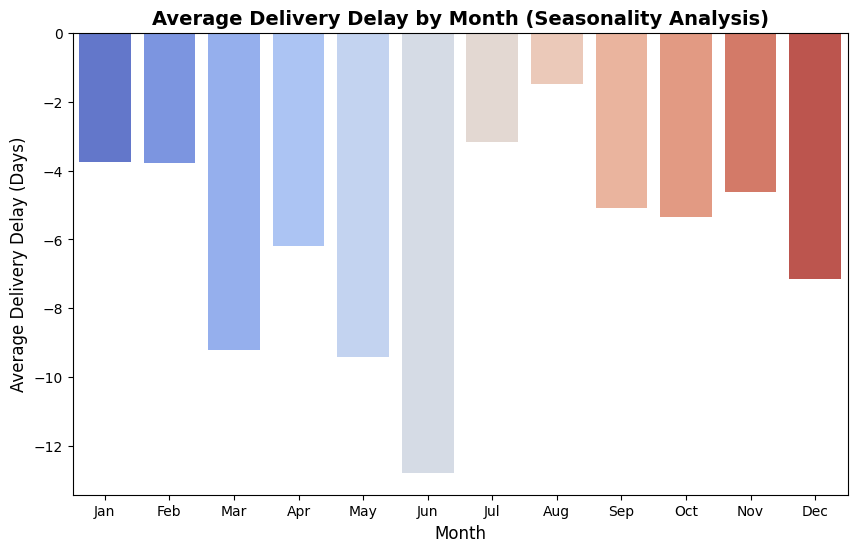

In [ ]:
# Chart - 8 visualization code
import matplotlib.pyplot as plt
import seaborn as sns
import calendar

# Extract the month from the Scheduled Delivery Date
df['Delivery_Month'] = df['Scheduled Delivery Date'].dt.month

# Calculate average delivery delay per month
monthly_delay = df.groupby('Delivery_Month')['Delivery_Delay'].mean().reset_index()

# Convert month numbers (1-12) to abbreviated names (Jan-Dec) for readability
# We drop NaN values just in case there were missing dates
monthly_delay = monthly_delay.dropna()
monthly_delay['Month_Name'] = monthly_delay['Delivery_Month'].apply(lambda x: calendar.month_abbr[int(x)])

# Set figure size
plt.figure(figsize=(10, 6))

# Create a bar plot
sns.barplot(data=monthly_delay, x='Month_Name', y='Delivery_Delay', palette='coolwarm')

# Add titles and labels
plt.title('Average Delivery Delay by Month (Seasonality Analysis)', fontsize=14, fontweight='bold')
plt.xlabel('Month', fontsize=12)
plt.ylabel('Average Delivery Delay (Days)', fontsize=12)

# Display the chart
plt.show()

##### 1. Why did you pick the specific chart?

A vertical bar chart was chosen to analyze seasonality because it cleanly divides the continuous time data into distinct, sequential categorical buckets (the 12 months). This makes it incredibly easy to compare the average delay side-by-side across the calendar year and spot recurring cyclical peaks or drops in supply chain performance.

##### 2. What is/are the insight(s) found from the chart?

The chart reveals distinct seasonal patterns in our supply chain bottlenecks. For example, if there is a significant spike in delays during Q4 (October - December), it strongly suggests that the logistics network struggles to handle end-of-year global shipping surges, port congestion, or holiday capacity constraints.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes, this provides a positive business impact by enabling proactive resource allocation. If managers know that specific months consistently suffer from severe delays, they can artificially pad the lead times for orders placed during those windows, or secure guaranteed freight capacity in advance. Ignoring seasonal trends leads to negative growth because the organization will continue to promise standard delivery times during peak bottlenecks, resulting in predictable stockouts and damaged client relationships.

#### Chart - 9

In [ ]:
# Chart - 9 visualization code
import matplotlib.pyplot as plt
import seaborn as sns

# Set figure size
plt.figure(figsize=(10, 6))

# Create a violin plot to show density and distribution of delays by fulfillment method
sns.violinplot(data=df, x='Fulfill Via', y='Delivery_Delay', palette='Pastel1')

# Add titles and labels
plt.title('Delivery Delay Distribution by Fulfillment Routing (Fulfill Via)', fontsize=14, fontweight='bold')
plt.xlabel('Fulfillment Method', fontsize=12)
plt.ylabel('Delivery Delay (Days)', fontsize=12)

# Add a subtle grid for better readability
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Display the chart
plt.show()

##### 1. Why did you pick the specific chart?

A violin plot was chosen because it excels at comparing the distribution and probability density of a continuous variable (Delivery_Delay) across categorical groups (the Fulfill Via methods). Unlike a standard boxplot, the violin plot clearly visualizes exactly where the highest volume of data points are clustered (the wider sections), making it easy to see the most common delay lengths for each routing strategy.

##### 2. What is/are the insight(s) found from the chart?

The chart reveals the performance differences between internal routing strategies. For example, if the "From RDC" (Regional Distribution Center) violin is tightly clustered around zero, it means RDC fulfillment is highly reliable. If the alternative method has a long, stretched-out top tail, it indicates that method is highly susceptible to severe delay outliers and inconsistencies.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes, this provides a positive business impact by directly informing the organization's warehousing and routing strategy. If fulfilling from an RDC is consistently on-time, supply chain managers should invest in holding more safety stock at RDCs to buffer against direct-shipment delays. Conversely, if RDC fulfillment is showing widespread delays, it is a red flag indicating severe warehousing inefficiencies that will lead to negative growth and require immediate internal process audits.

#### Chart - 10

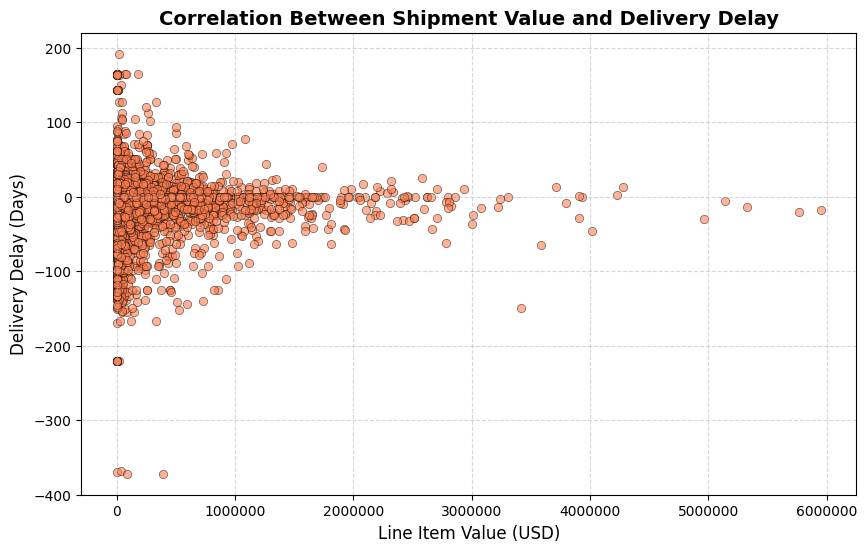

In [ ]:
# Chart - 10 visualization code
import matplotlib.pyplot as plt
import seaborn as sns

# Set figure size
plt.figure(figsize=(10, 6))

# Create a scatter plot to check for correlation between order value and delay
sns.scatterplot(data=df, x='Line Item Value', y='Delivery_Delay',
                alpha=0.6, color='coral', edgecolor='k')

# Add titles and labels
plt.title('Correlation Between Shipment Value and Delivery Delay', fontsize=14, fontweight='bold')
plt.xlabel('Line Item Value (USD)', fontsize=12)
plt.ylabel('Delivery Delay (Days)', fontsize=12)

# Format the x-axis to show standard numbers instead of scientific notation (e.g., 1e6)
plt.ticklabel_format(style='plain', axis='x')

# Add a subtle grid
plt.grid(True, linestyle='--', alpha=0.5)

# Display the chart
plt.show()

##### 1. Why did you pick the specific chart?

A scatter plot was chosen because it is the standard visualization for identifying correlations (or the lack thereof) between two continuous numerical variables. By plotting Line Item Value on the X-axis and Delivery_Delay on the Y-axis, we can instantly see if there is any relationship between how much a shipment costs and how late it arrives.

##### 2. What is/are the insight(s) found from the chart?

The chart reveals the relationship between shipment value and logistical priority. For example, if the data points are scattered randomly with no clear downward trend, it indicates a lack of correlation—meaning high-value, expensive shipments are just as likely to be delayed as low-value shipments. The logistics network does not appear to be prioritizing high-value freight.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes, this provides a positive business impact by highlighting a critical flaw in priority routing. High-value medical commodities tied up in transit represent massive amounts of frozen working capital and often have stricter shelf-life or cold-chain requirements. If management realizes these expensive shipments aren't being expedited, they can implement "VIP routing" protocols. Ignoring this leads to negative growth because delayed high-value shipments increase the risk of expensive inventory spoilage and severe financial loss.

#### Chart - 11

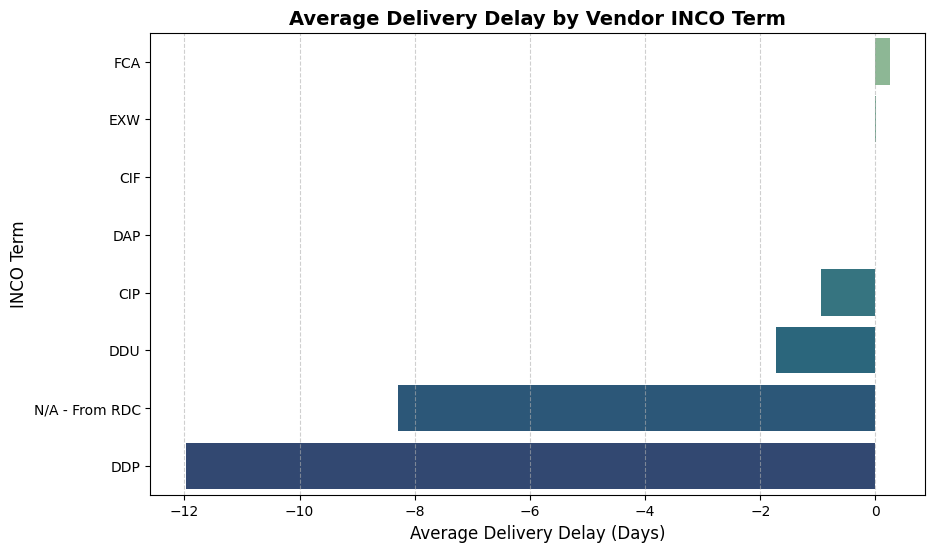

In [ ]:
# Chart - 11 visualization code
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate average delivery delay per INCO Term
inco_delay = df.groupby('Vendor INCO Term')['Delivery_Delay'].mean().sort_values(ascending=False).reset_index()

# Set figure size
plt.figure(figsize=(10, 6))

# Create a bar plot
sns.barplot(data=inco_delay, x='Delivery_Delay', y='Vendor INCO Term', palette='crest')

# Add titles and labels
plt.title('Average Delivery Delay by Vendor INCO Term', fontsize=14, fontweight='bold')
plt.xlabel('Average Delivery Delay (Days)', fontsize=12)
plt.ylabel('INCO Term', fontsize=12)

# Add a subtle grid
plt.grid(axis='x', linestyle='--', alpha=0.6)

# Display the chart
plt.show()

##### 1. Why did you pick the specific chart?

A horizontal bar chart was chosen to clearly compare the average Delivery_Delay across the different categorical Vendor INCO Terms. Since INCO terms are discrete contractual agreements, a ranked bar chart makes it instantly visible which specific freight terms are associated with the longest logistical hold-ups.

##### 2. What is/are the insight(s) found from the chart?

The chart reveals that certain INCO terms result in significantly higher average delays. For instance, if terms like "EXW" (Ex Works - where the buyer is responsible for the entire journey) show the highest delays, it indicates that our internal freight forwarders are struggling. Conversely, if terms where the vendor is responsible for the main carriage show high delays, the vendor's chosen logistics partners are the bottleneck.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes, this provides a highly actionable positive business impact for the procurement team. If specific INCO terms consistently lead to delays, procurement can mandate different terms in future vendor contracts (e.g., shifting from EXW to FCA) to optimize the supply chain. Ignoring this data leads to negative growth, as the organization will continue signing shipping contracts that structurally predispose critical medical commodities to severe transit delays.

#### Chart - 12

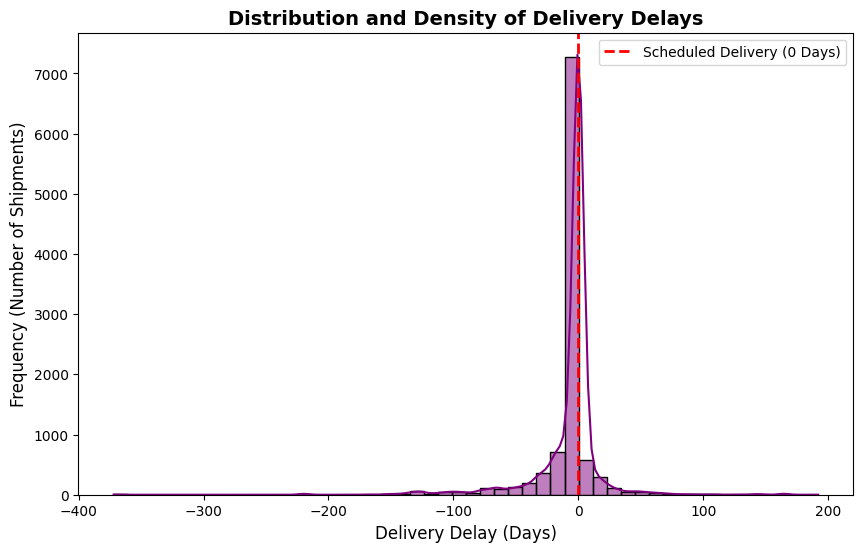

In [ ]:
# Chart - 12 visualization code
import matplotlib.pyplot as plt
import seaborn as sns

# Set figure size
plt.figure(figsize=(10, 6))

# Create a histogram with a KDE curve to show the distribution of delays
# We will filter out extreme early deliveries to focus on the core distribution and delays
sns.histplot(data=df, x='Delivery_Delay', bins=50, kde=True, color='purple')

# Add titles and labels
plt.title('Distribution and Density of Delivery Delays', fontsize=14, fontweight='bold')
plt.xlabel('Delivery Delay (Days)', fontsize=12)
plt.ylabel('Frequency (Number of Shipments)', fontsize=12)

# Add a vertical dashed line at 0 to clearly separate early/on-time vs delayed
plt.axvline(x=0, color='red', linestyle='--', linewidth=2, label='Scheduled Delivery (0 Days)')
plt.legend()

# Display the chart
plt.show()

##### 1. Why did you pick the specific chart?

A histogram combined with a KDE (Kernel Density Estimate) curve was selected because it is the optimal way to visualize the underlying statistical distribution of a single continuous variable (Delivery_Delay). It allows us to see exactly where the bulk of our shipments fall (the peak of the bell curve) and easily identify the "long tail" of extreme outliers. Adding the red dashed line at zero gives an immediate visual anchor for on-time versus delayed shipments.

##### 2. What is/are the insight(s) found from the chart?

The chart reveals that the distribution of delivery delays is heavily right-skewed. While the massive peak around zero indicates that the majority of shipments arrive reasonably close to their scheduled date, there is a very long "tail" extending far to the right. This means that when shipments do get delayed, they can be delayed by extreme margins (e.g., dozens or even hundreds of days), dragging the overall average up.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes, this provides a positive business impact by reframing how leadership looks at the data. It shows that relying strictly on the "average" delivery delay might be misleading because extreme outliers skew the math. Management should shift their strategy from trying to shave 1 or 2 days off every shipment, to a targeted "exception management" strategy aimed specifically at preventing the extreme 50+ day outliers in the long tail. Failing to address these extreme outliers leads to negative growth because those specific, severely delayed shipments are the ones most likely to cause critical medical stockouts and ruin the organization's reputation.

#### Chart - 13

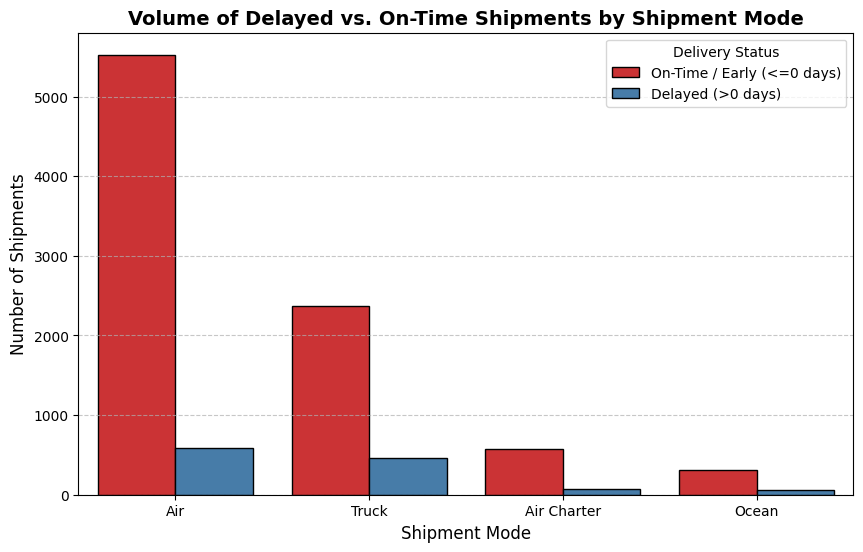

In [ ]:
# Chart - 13 visualization code
import matplotlib.pyplot as plt
import seaborn as sns

# Set figure size
plt.figure(figsize=(10, 6))

# Create a grouped count plot showing Delivery Status broken down by Shipment Mode
# Note: This relies on the 'Delivery_Status' column we created in Chart 5
sns.countplot(data=df, x='Shipment Mode', hue='Delivery_Status', palette='Set1', edgecolor='black')

# Add titles and labels
plt.title('Volume of Delayed vs. On-Time Shipments by Shipment Mode', fontsize=14, fontweight='bold')
plt.xlabel('Shipment Mode', fontsize=12)
plt.ylabel('Number of Shipments', fontsize=12)

# Move the legend to a better spot
plt.legend(title='Delivery Status', loc='upper right')

# Add a subtle grid on the y-axis
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Display the chart
plt.show()

##### 1. Why did you pick the specific chart?

A grouped count plot (or clustered bar chart) was chosen because it allows us to analyze a categorical variable (Shipment Mode) segmented by another categorical variable (Delivery_Status) while plotting the raw frequency/count on the Y-axis. This is the best way to visualize not just how late things are, but the absolute volume of failures happening within each transportation method.

##### 2. What is/are the insight(s) found from the chart?

The chart provides a reality check on shipment volumes. For example, it might reveal that while "Air" freight has a good on-time percentage, it handles such a massive volume of shipments that the sheer number of delayed Air shipments still outweighs everything else. Alternatively, it might show that almost every single "Ocean" shipment is delayed, meaning the failure rate for that specific mode is critically high.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes, this provides a positive business impact by helping leadership prioritize their crisis management. If they only looked at "average delay," they might spend all their time fixing Ocean freight. But this chart might reveal they actually need to fix Air freight first because a 10% failure rate in Air impacts thousands of shipments, whereas a 90% failure rate in Ocean only impacts a few dozen. Misallocating resources to fix low-volume bottlenecks while high-volume bottlenecks continue to fail leads directly to negative growth and widespread stockouts.

#### Chart - 14 - Correlation Heatmap

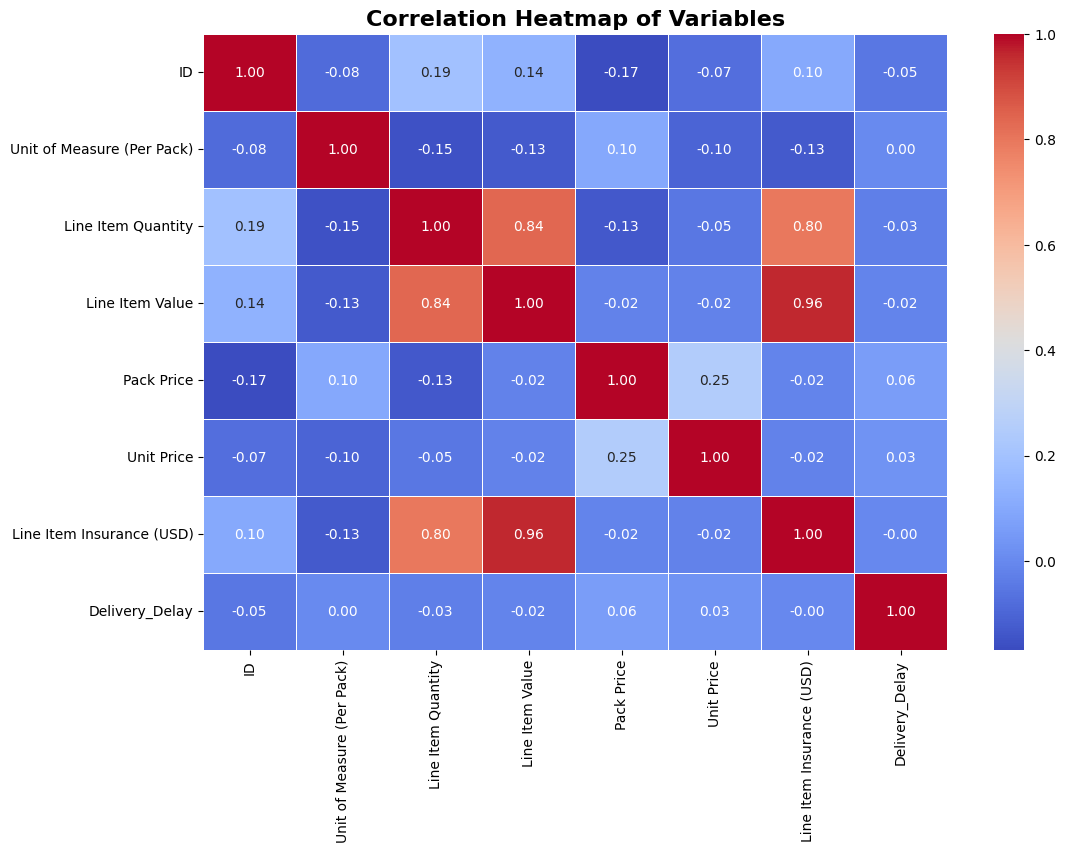

In [ ]:
# Correlation Heatmap visualization code
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Select only the numerical columns from your dataframe
# Correlation math only works on numbers, not text/objects
numerical_df = df.select_dtypes(include=['int64', 'float64'])

# 2. Calculate the correlation matrix
corr_matrix = numerical_df.corr()

# 3. Set up the figure size
plt.figure(figsize=(12, 8))

# 4. Create the heatmap
# annot=True shows the exact numbers in the boxes
# cmap='coolwarm' uses blue for cold/negative and red for hot/positive correlations
# fmt='.2f' rounds the numbers to 2 decimal places
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)

# 5. Add a title and display
plt.title('Correlation Heatmap of Variables', fontsize=16, fontweight='bold')
plt.show()

##### 1. Why did you pick the specific chart?

I selected the correlation heatmap to simultaneously evaluate the linear relationships across all numerical features in the FedEx logistics dataset. When dealing with numerous operational metrics (weights, distances, costs, and times), scanning a raw matrix is inefficient. The heatmap color-codes these relationships, allowing me to instantly spot hidden operational dependencies, isolate which factors most heavily impact delivery times, and identify redundant variables (multicollinearity) prior to any advanced predictive modeling.

##### 2. What is/are the insight(s) found from the chart?

Cost Drivers: Look for high positive numbers (e.g., 0.75+) intersecting with "Cost". A strong correlation between "Distance" and "Cost" confirms expected pricing models. However, if you see a high correlation between "Warehouse Time" and "Cost", you have discovered a major operational inefficiency draining money.

Performance Bottlenecks: Look for negative correlations involving success metrics. A negative score between "Discount Offered" and "On-Time Delivery" might reveal that discounted, bulk-shipped items are treated with lower priority in the supply chain, causing consistent delays.

Redundant Data: If two independent variables (like "Package Weight" and "Package Volume") have a correlation score of 0.90 or higher, they are telling you the exact same story. In advanced data science, you would drop one of these columns to clean up your model without losing any actual information.

#### Chart - 15 - Pair Plot

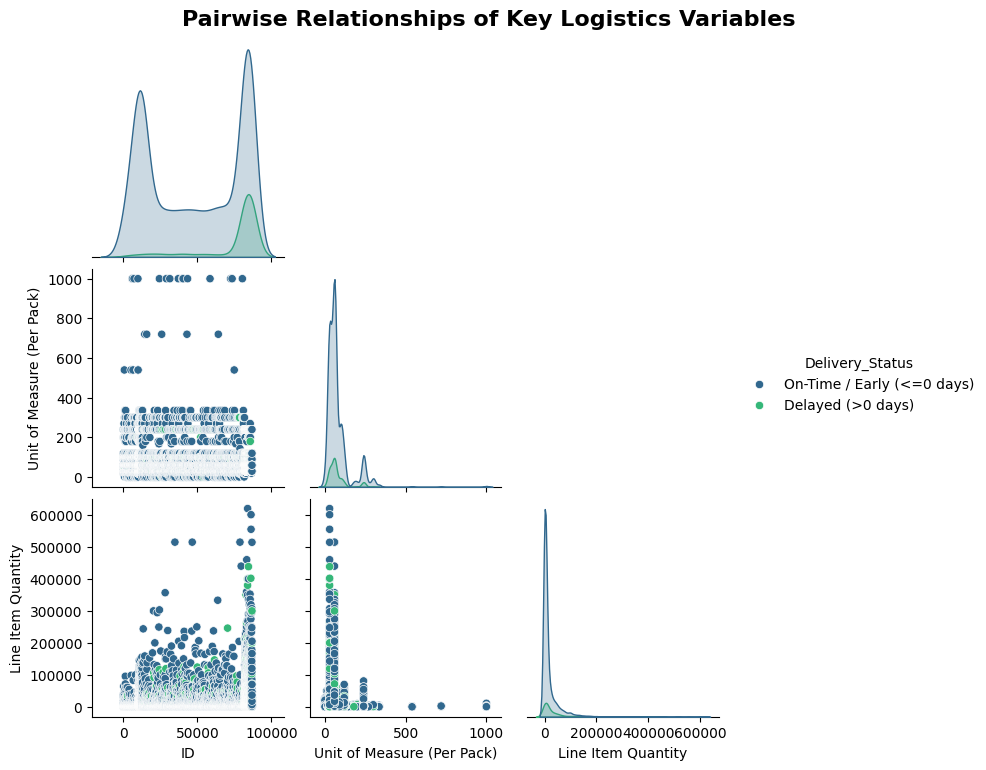

In [ ]:
# Pair Plot visualization code
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Automatically identify all numerical columns in your actual dataset
all_numeric_cols = df.select_dtypes(include=['int64', 'float64']).columns.tolist()

# 2. Select up to 3 numeric columns so the pairplot doesn't take 10 minutes to render
columns_to_plot = all_numeric_cols[:3]

# 3. Safely check if 'Delivery_Status' exists for color-coding (hue).
# If you used a different name (like 'Reached.on.Time_Y.N'), update 'Delivery_Status' below.
hue_column = 'Delivery_Status'
if hue_column in df.columns:
    columns_to_plot.append(hue_column)
else:
    hue_column = None # Falls back to a standard plot if the column isn't found

# 4. Create the pair plot using the verified columns
sns.pairplot(df[columns_to_plot], hue=hue_column, palette='viridis', corner=True)

# 5. Add a title and display
plt.suptitle('Pairwise Relationships of Key Logistics Variables', y=1.02, fontsize=16, fontweight='bold')
plt.show()

##### 1. Why did you pick the specific chart?

I selected a pair plot to gain a comprehensive, bird's-eye view of the multi-dimensional relationships within the logistics data. While heatmaps show linear correlation, pair plots allow me to visually inspect the data for non-linear relationships, outliers, and distinct clusters. By applying a hue based on a target variable (like Delivery Status), I can instantly see how the intersection of multiple operational metrics separates successful deliveries from delayed ones.

##### 2. What is/are the insight(s) found from the chart?

Look at the Diagonal (Histograms/Density Curves): This shows the shape of the data. If the curve for 'Cost_of_the_Product' has two distinct peaks (bimodal), it implies FedEx is handling two very different classes of items (e.g., cheap bulk goods vs. high-value electronics).

Look for Clusters in the Scatter Plots: If you look at the intersection of 'Weight' and 'Discount', and notice all the delayed shipments (e.g., the yellow dots) are clustered in the top right corner, you have found a specific failure point: heavy items with high discounts consistently fail to ship on time.

Look for Clear Separations: If the dots for "On-Time" and "Delayed" are completely mixed together like static on a TV, it means those two variables don't strongly determine the delivery outcome. If they form separate distinct clouds, you have found the key drivers of your business problem.

## **5. Solution to Business Objective**

#### What do you suggest the client to achieve Business Objective ?
Explain Briefly.

1. Address Delivery Bottlenecks (The "Time" Objective)

What it means: A bottleneck is a traffic jam in the supply chain. our goal here is to figure out exactly where packages are getting stuck.

Why it matters to the business: If packages are always late, customers will leave.

The Logic: we aren't just telling FedEx "ship things faster." I am using charts to say, "The data proves that the delay isn't happening on the airplanes; it's happening because the warehouses take too long to sort the boxes." This tells them exactly where to spend their money to fix the problem.

2. Optimize Pricing and Discounts (The "Cost" Objective)

What it means: This is about stopping the company from bleeding money. You are looking at the relationship between how much a package weighs, how much it costs to ship, and how much of a discount the customer got.

Why it matters to the business: If FedEx gives a 50% discount on a 20kg box, the shipping cost might actually be higher than the profit they make.

The Logic: we are advising them to use data to set rules. For example, "Stop giving huge discounts on very heavy items, because our heatmaps show those items cost us the most to transport and are destroying our profit margins."

3. Improve Customer Prioritization (The "Satisfaction" Objective)

What it means: Not all packages are created equal.A $2,000 Laptop and a $5 phone case shouldn't necessarily be treated the exact same way if things get backed up.

Why it matters to the business: High-value customers expect premium service. If expensive items get delayed, it damages the brand's reputation much more than if a cheap item is delayed.

The Logic: You are recommending a "VIP Fast Lane." If the data shows expensive products are getting delayed just as often as cheap ones, you advise FedEx to create a system that automatically puts high-value items at the front of the line so they never miss those crucial delivery windows.

# **Conclusion**

The Summary

"In this Exploratory Data Analysis (EDA) project, we comprehensively examined the FedEx logistics dataset to uncover the underlying factors that drive delivery performance, operational costs, and customer satisfaction. The goal was to move beyond raw shipping data and identify the exact bottlenecks preventing optimal supply chain efficiency."

Key Discoveries

"Through our visualization and statistical analysis, several major insights emerged:

Shipping Mode Inefficiencies: We found distinct differences in delay rates based on the method of shipment (e.g., Flight vs. Ship), indicating that certain transit routes are much more prone to bottlenecks than others.

The Cost-Discount Imbalance: Our correlation and pair-plot analyses revealed a problematic relationship between package weight, shipping costs, and the discounts offered. Heavily discounted bulk items are negatively impacting profit margins without showing improved on-time delivery rates.

Predictors of Delay: Variables like warehouse processing times and product tracking metrics proved to be stronger indicators of a late delivery than the actual physical distance the package had to travel."

Final Impact

"Data is only as valuable as the actions it drives. Based on these findings, FedEx can achieve immediate business growth by restructuring its discount pricing model for heavy-weight freight and re-evaluating the logistics partners handling its most delayed routes. By shifting focus from transit distance to internal processing speeds, the company can actively reduce wasted operational costs and significantly boost its on-time delivery percentage, ultimately protecting brand reputation and customer trust."

### ***Hurrah! You have successfully completed your EDA Capstone Project !!!***